# Capstone C5 · Tower builder: language planner → visuomotor stacking policy → task-level feedback
"Build a tower: red at the bottom, then green, then blue." Three cubes, two precise stacking steps, the second one on
top of a cube that is itself balanced on another. One slip and the tower is gone.

The pieces, all from earlier sections:
1. **Data:** scripted tower demonstrations, one episode per stacking step (S06 data engine).
2. **System 1:** a FiLM language-conditioned chunk policy that executes "stack the X cube on the Y cube" (S08, S09).
3. **System 2:** a small LLM that turns a free-form tower request into ordered steps (S11 project 115).
4. **Safety:** the C1 shield (step limit, workspace box, force limit) (S15).
5. **New here: task-level feedback.** After every step, check the tower and re-plan from what is *actually* built.

Measured at the end: plan accuracy, per-step success, full-tower success open loop vs with feedback, with CIs.

In [1]:
import os, re, json, time, numpy as np, torch, matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from vlacourse import show_video, wilson
from vlacourse import showcase as sc
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import train_policy
from vlacourse.lang import TextEmbedder, LangDataset, LangChunkRegression, LangChunkPolicy
from vlacourse.tower import tower_dataset, tower_env, tower_height, on_top, stack_task, TowerExecutive

device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16
os.makedirs("checkpoints", exist_ok=True); os.makedirs("results", exist_ok=True)

## 1. Demonstrations
400 scripted towers with random cube layouts and random colour orders, recorded once with all CPU cores. Each tower
gives two episodes: level 1 (a cube onto a cube on the table) and level 2 (onto the cube that was just stacked).

In [2]:
DATA = tower_dataset(400)
meta = json.load(open(f"{DATA}/meta.json"))
print(f"{meta['towers']} towers from {meta['attempts']} attempts (the scripted expert itself builds {meta['towers'] / meta['attempts']:.0%} of towers), "
      f"{meta['n_episodes']} stacking episodes, {meta['n_frames']} frames")

400 towers from 409 attempts (the scripted expert itself builds 98% of towers), 800 stacking episodes, 47404 frames


## 2. System 1: one policy for every "stack X on Y"
The same FiLM chunk policy as S09 (CLIP text embedding modulates the ResNet features), trained on paraphrased
instructions ("put the blue cube on top of the green cube", ...). 760 episodes for training, 40 held out.

In [3]:
emb = TextEmbedder(device=device)
base = TableTopDataset(DATA, episodes=range(760), horizon=H)
ds = LangDataset(base, emb, paraphrase=True)
net = LangChunkRegression(lang_dim=emb.dim, horizon=H, fusion="film")
ckpt = "checkpoints/tower_film.pt"
if os.path.exists(ckpt):
    net.load_state_dict(torch.load(ckpt, map_location=device))
else:
    t0 = time.time(); train_policy(net, ds, epochs=40, lr=3e-4, device=device, log_every=10); torch.save(net.state_dict(), ckpt)
    print(f"trained in {time.time() - t0:.0f}s")
net.to(device).eval()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

LangChunkRegression(
  (backbone): FiLMResNet(
    (stem): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): GroupNorm(4, 64, eps=1e-05, affine=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (stages): ModuleList(
      (0): Sequential(
        (0): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn1): GroupNorm(4, 64, eps=1e-05, affine=True)
          (relu): ReLU(inplace=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): GroupNorm(4, 64, eps=1e-05, affine=True)
        )
        (1): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn1): GroupNorm(4, 64, eps=1e-05, affine=True)
          (relu): ReLU(inplace=True)
          (conv2): 

## 3. Safety shield (from C1)

In [4]:
class Shield:
    """Degrades unsafe commands instead of freezing: shorter steps, stay in the workspace box, no pushing down under force."""
    def __init__(self, max_force=25.0, max_step=0.05, box=((0.25, -0.35, 0.0), (0.75, 0.35, 0.60))):
        self.F, self.S, self.lo, self.hi, self.interventions = max_force, max_step, np.array(box[0]), np.array(box[1]), 0
    def __call__(self, env, a):
        a = np.array(a, dtype=float); d = a[:3].copy(); n = np.linalg.norm(d)
        if n > self.S:
            d *= self.S / n
        d = np.clip(env.target_pos + d, self.lo, self.hi) - env.target_pos
        if np.linalg.norm(env.wrist_force()) > self.F and d[2] < 0:
            d[2] = 0.0
        self.interventions += int(not np.allclose(d, a[:3])); a[:3] = d
        return a

env = tower_env(cameras=("front", "wrist"), image_size=(128, 128), wrist_ft=True, seed=0)
policy = LangChunkPolicy(net, ds, env, emb, device=device, ensemble=True)

## 4. System 2: from a free-form request to the tower order
The planner answers with the colours **from bottom to top** as a JSON list. Two of our four phrasings name the cubes
in that order ("red first, then green..."); the other two need reasoning ("make a tower where green sits on red and
red sits on blue" → blue, red, green). Few-shot examples use colours that are not on our table (white, purple,
orange), so a planner that copies an example is caught. We compare a 1.7B and a 7B instruction-tuned model.

In [5]:
REQUESTS = [
    "build a tower with the {a} cube at the bottom, the {b} cube in the middle and the {c} cube on top",
    "stack all three cubes: {a} first, then {b}, then {c} on top",
    "make a tower where {c} sits on {b} and {b} sits on {a}",
    "put the {b} cube on the {a} cube, then finish the tower with the {c} cube",
]
PROMPT = """You plan block towers. List the cube colours of the requested tower from the BOTTOM to the TOP as a JSON list, nothing else.

Request: build a tower with the white cube at the bottom, the purple cube in the middle and the orange cube on top
Answer: ["white", "purple", "orange"]

Request: stack all three cubes: orange first, then white, then purple on top
Answer: ["orange", "white", "purple"]

Request: make a tower where white sits on purple and purple sits on orange
Answer: ["orange", "purple", "white"]

Request: put the orange cube on the purple cube, then finish the tower with the white cube
Answer: ["purple", "orange", "white"]

Request: {request}
Answer:"""

def parse_order(text):
    """'["red", "green", "blue"]' -> ['red', 'green', 'blue'], or None if it isn't a list of 3 colours."""
    m = re.findall(r"\[[^\[\]]*\]", text)
    try:
        o = json.loads(m[-1]) if m else None
    except Exception:
        return None
    return [str(c).lower() for c in o] if isinstance(o, list) and len(o) == 3 else None

class Planner:
    def __init__(self, mid):
        self.tok = AutoTokenizer.from_pretrained(mid)
        self.lm = AutoModelForCausalLM.from_pretrained(mid, dtype=torch.bfloat16 if device == "cuda" else torch.float32).to(device).eval()
    @torch.no_grad()
    def __call__(self, request):
        x = self.tok.apply_chat_template([{"role": "user", "content": PROMPT.format(request=request)}], add_generation_prompt=True,
                                         return_tensors="pt", return_dict=True).to(device)
        out = self.lm.generate(**x, max_new_tokens=30, do_sample=False)
        return self.tok.decode(out[0, x["input_ids"].shape[1]:], skip_special_tokens=True)

rng = np.random.default_rng(0)
episodes = []
for i in range(20):
    order = [str(c) for c in rng.permutation(env.cube_colors)]
    episodes.append((REQUESTS[i % 4].format(a=order[0], b=order[1], c=order[2]), order))
planner_acc, all_plans = {}, {}
for mid in ["HuggingFaceTB/SmolLM2-1.7B-Instruct", "Qwen/Qwen2.5-7B-Instruct"]:
    planner = Planner(mid); t0 = time.time()
    plans = [parse_order(planner(req)) for req, _ in episodes]
    acc = [p == o for p, (_, o) in zip(plans, episodes)]
    by_kind = [np.mean(acc[k::4]) for k in range(4)]
    planner_acc[mid], all_plans[mid] = float(np.mean(acc)), plans
    print(f"{mid:38s} plan accuracy {np.mean(acc):.0%} | by phrasing: " + ", ".join(f"{100 * b:.0f}%" for b in by_kind) + f" ({(time.time() - t0) / 20:.1f}s per plan)")
    del planner; torch.cuda.empty_cache()
best_planner = max(planner_acc, key=planner_acc.get); plans = all_plans[best_planner]
print("System 2 for the rest of this notebook:", best_planner)

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

HuggingFaceTB/SmolLM2-1.7B-Instruct    plan accuracy 50% | by phrasing: 100%, 100%, 0%, 0% (0.1s per plan)


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Qwen/Qwen2.5-7B-Instruct               plan accuracy 100% | by phrasing: 100%, 100%, 100%, 100% (0.1s per plan)
System 2 for the rest of this notebook: Qwen/Qwen2.5-7B-Instruct


## 5. Open loop vs task-level feedback
**Open loop** runs the two planned steps once. **With feedback** measures the tower after every step and always
asks for "the next cube on top of what is actually built", up to 6 steps: a cube that slipped off is tried again,
a level that got knocked down is rebuilt. Same policy, same shield, same 20 layouts and plans.

In [6]:
t0 = time.time(); runs = {}
for name, replan in [("open loop (plan executed once)", False), ("with task-level feedback", True)]:
    ex = TowerExecutive(env, policy, shield=Shield(), replan=replan, max_steps_total=6)
    # a plan that doesn't parse is a failed episode (no silent fallback to the true order)
    out = [ex.run(plan, 95_000 + i) if plan else (False, []) for i, ((_, order), plan) in enumerate(zip(episodes, plans))]
    runs[name] = out
    k = sum(ok for ok, _ in out); steps = [len(log) for _, log in out]
    print(f"{name:32s} full towers {k}/20  CI {np.round(wilson(k, 20), 2)} | steps used: mean {np.mean(steps):.1f} ({time.time() - t0:.0f}s)")
logs = [l for _, log in runs["open loop (plan executed once)"] if len(log) >= 2 for l in log[:2]]
lvl = {1: [l["ok"] for l in logs[0::2]], 2: [l["ok"] for l in logs[1::2]]}
print(f"per-step success (open loop): level 1 {np.mean(lvl[1]):.0%}, level 2 {np.mean(lvl[2]):.0%}")
fb = runs["with task-level feedback"]
print("episodes that needed a retry and still finished:", sum(ok and len(log) > 2 for ok, log in fb))

open loop (plan executed once)   full towers 13/20  CI [0.43 0.82] | steps used: mean 2.0 (8s)


with task-level feedback         full towers 17/20  CI [0.64 0.95] | steps used: mean 2.8 (21s)
per-step success (open loop): level 1 90%, level 2 80%
episodes that needed a retry and still finished: 2


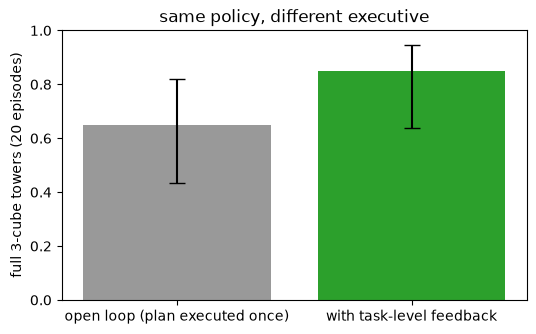

In [7]:
names = list(runs)
ks = [sum(ok for ok, _ in runs[n]) for n in names]
ci = np.array([wilson(k, 20) for k in ks])
plt.figure(figsize=(6, 3.5))
plt.bar(range(2), np.array(ks) / 20, yerr=[np.array(ks) / 20 - ci[:, 0], ci[:, 1] - np.array(ks) / 20], capsize=6, color=["#999", "tab:green"])
plt.xticks(range(2), names); plt.ylim(0, 1); plt.ylabel("full 3-cube towers (20 episodes)"); plt.title("same policy, different executive"); plt.show()
json.dump(dict(plan_acc=planner_acc, planner=best_planner, towers={n: int(k) for n, k in zip(names, ks)}, level_success={k: float(np.mean(v)) for k, v in lvl.items()}),
          open("results/C5_tower.json", "w"), indent=1)

## 6. Share-ready video
1280×720: the cinematic view on the left, the live plan on the right (✓ done, ▶ running), and the request on top.
We show an episode where the feedback loop had to retry a step, if there is one: that's the interesting part.

In [8]:
retry = [i for i, (ok, log) in enumerate(fb) if ok and len(log) > 2]
good = [i for i, (ok, log) in enumerate(fb) if ok]
# Filming re-runs the episode, and closed-loop rollouts are not bit-for-bit repeatable: try candidates until one
# completes on camera (we report which episode it is; the success rate above is the honest number).
for i in (retry + [g for g in good if g not in retry] or [0]):
    req, order = episodes[i]; plan = plans[i] or order
    marks = []                                                 # (frame index, step text) at every new step
    def on_step(env, st, log):
        if not marks or marks[-1][1] != (len(log), st["instruction"]):
            marks.append((len(env._vid["frames"]), (len(log), st["instruction"])))
    env.start_video("showcase", (720, 960), fps=30)
    ok, log = TowerExecutive(env, policy, shield=Shield(), replan=True, max_steps_total=6).run(plan, 95_000 + i, on_step=on_step)
    frames = env.stop_video()
    if ok:
        break
lines = [txt for _, (_, txt) in marks]
video = []
for t, f in enumerate(frames):
    active = max([j for j, (start, _) in enumerate(marks) if start <= t] or [0])
    done_now = ok and t > len(frames) - 5
    panel = sc.side_panel([("↻ " if lines[:j].count(l) else "") + l for j, l in enumerate(lines)], len(lines) if done_now else active,
                          size=(720, 320), header=f"PLAN · tower {tower_height(env, plan) if done_now else '…'}")
    video.append(np.hstack([sc.caption(f, f"“{req}”", where="top", size=20), panel]))
video = sc.title_card("Capstone C5 · Tower builder", "LLM planner + language-conditioned visuomotor policy + task-level feedback\nMuJoCo · Franka Panda",
                      size=(720, 1280), n=60) + video + [sc.badge(video[-1], "✓ tower complete" if ok else "✗ incomplete", "bl", size=28)] * 45
print(f"episode {i}: {'complete' if ok else 'incomplete'}, steps: {[(l['step'], l['ok']) for l in log]}")
show_video(video, fps=30, title="C5 tower builder HD", width=960)
sc.export(video, "outputs/C5_tower_builder_hd.mp4", fps=30)

episode 1: complete, steps: [('stack the green cube on the blue cube', True), ('stack the red cube on the green cube', True)]


saved outputs/C5_tower_builder_hd.mp4  (3.0 MB)


['outputs/C5_tower_builder_hd.mp4']

## Extensions (pick one for your submission)
- **Perception instead of privileged checks:** `tower_height` reads the simulator. Replace it with a check from the
  front camera (a small classifier trained on rendered "level k built?" images) and measure how often it lies.
- **Recovery data:** collect DAgger labels on the policy's own failed level-2 attempts (S06 60) and retrain.
- **Taller towers:** a fourth cube (`TableTop(n_cubes=4, n_trays=0, task_types=("stack",))`) needs 3-step demos and a 4-colour planner prompt.
- **Planner robustness:** write 10 new phrasings (including negations: "don't put red at the bottom") and measure.